### Ableitungen: Änderungsrate, Tangente, Extrem- und Wendepunkte - Übungen

In diesem Notebook geht es um die **Differentialrechnung**: Wie schnell ändert sich eine Größe? Vom Differenzenquotienten (mittlere
Änderungsrate) kommst du über einen Grenzwert zur **Ableitung** (momentane Änderungsrate). Mit Ableitungen bestimmst du Tangenten,
Monotonie, Hoch-, Tief- und Wendepunkte und löst Optimierungsaufgaben.

sympy kann Grenzwerte (`limit`) und Ableitungen (`diff`) exakt berechnen. Rechne die Ableitungen trotzdem zuerst selbst mit den
Ableitungsregeln und prüfe dann mit sympy.

Vorausgesetzt werden die Notebooks *Terme*, *Gleichungen* und *Funktionen*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

**Brüche und Kommazahlen:** Python rechnet `1/6` oder `0.5` sofort als Kommazahl, bevor sympy die Zahl sieht.
Die erwarteten Ausgaben sind aber mit exakten Brüchen berechnet. Schreibe solche Zahlen deshalb mit `Rational`: `Rational(1, 6)` für 1/6,
`Rational('0.5')` für 0,5. Bei einer Division ganzer Zahlen genügt es, eine davon mit `Integer` zu schreiben: `Integer(1) / 6`.
Aufgaben, bei denen das nötig ist, haben einen entsprechenden Hinweis.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und matplotlib, schaltet die Formel-Ausgabe ein
und legt die Variablen `x`, `h`, `a` und `b` an.

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
x, h, a, b = symbols('x h a b')

## 1. Mittlere Änderungsrate

#### Differenzenquotient und Sekante

Die **mittlere Änderungsrate** einer Funktion f auf dem Intervall [a, b] ist der **Differenzenquotient**

(f(b) − f(a)) / (b − a)

Geometrisch ist das die Steigung der **Sekante** durch die Punkte (a | f(a)) und (b | f(b)).

In [ ]:
def f(x):
    return x**2

m = (f(3) - f(1)) / Integer(3 - 1)
display(m)
sekante = m * (x - 1) + f(1)
display(expand(sekante))
plot(f(x), sekante, (x, -0.5, 3.5), legend=True);

#### Aufgabe 1.1

Berechne die mittlere Änderungsrate von `f(x) = x²` auf dem Intervall [1, 4].

**Erwartete Ausgabe:**

$\displaystyle 5$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return x**2

(f(4) - f(1)) / Integer(4 - 1)
```

</details>

#### Aufgabe 1.2

Berechne die mittlere Änderungsrate von `f(x) = x³ − 2x` auf [−1, 2].

**Erwartete Ausgabe:**

$\displaystyle 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return x**3 - 2*x

(f(2) - f(-1)) / Integer(2 - (-1))
```

</details>

#### Aufgabe 1.3

Berechne die mittleren Änderungsraten von `f(x) = x²` auf den Intervallen [1, 2], [1; 1,1] und [1; 1,01] exakt. Gib sie als Liste aus.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \left[ 3, \  \frac{21}{10}, \  \frac{201}{100}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return x**2

[(f(1 + d) - f(1)) / d for d in [Integer(1), Rational(1, 10), Rational(1, 100)]]
```

</details>

#### Aufgabe 1.4

**Temperatur:** Um 8 Uhr ist es 12 °C, um 14 Uhr 21 °C. Wie groß ist die mittlere Änderungsrate in °C pro Stunde?

**Erwartete Ausgabe:**

$\displaystyle \frac{3}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Rational(21 - 12, 14 - 8)
```

</details>

#### Aufgabe 1.5

Gib die Gleichung der Sekante von `f(x) = √x` durch die Punkte bei x = 1 und x = 4 aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{x}{3} + \frac{2}{3}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
m = (sqrt(4) - sqrt(1)) / 3
expand(m * (x - 1) + 1)
```

</details>

#### Aufgabe 1.6

Berechne den Differenzenquotienten `(f(x0 + h) − f(x0))/h` für `f(x) = x²` und `x0 = 3` vereinfacht.

**Erwartete Ausgabe:**

$\displaystyle h + 6$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return x**2

simplify((f(3 + h) - f(3)) / h)
```

</details>

## 2. Von der mittleren zur momentanen Änderungsrate

#### Der Grenzwert h → 0

Lässt man das Intervall immer kleiner werden (h → 0), geht die Sekantensteigung gegen die **Tangentensteigung**.
Dieser Grenzwert ist die **Ableitung** von f an der Stelle x₀:

f'(x₀) = lim (h → 0) (f(x₀ + h) − f(x₀)) / h

sympy berechnet Grenzwerte mit `limit(term, h, 0)`. Setzt man statt einer Zahl x₀ die Variable x ein, erhält man die
**Ableitungsfunktion** f'(x).

In [ ]:
def f(x):
    return x**2

dq = (f(3 + h) - f(3)) / h
display(simplify(dq))
display(limit(dq, h, 0))
limit((f(x + h) - f(x)) / h, h, 0)

#### Aufgabe 2.1

Berechne `f'(2)` für `f(x) = x³` mit dem Grenzwert des Differenzenquotienten.

**Erwartete Ausgabe:**

$\displaystyle 12$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return x**3

limit((f(2 + h) - f(2)) / h, h, 0)
```

</details>

#### Aufgabe 2.2

Berechne die Ableitungsfunktion von `f(x) = x³` mit dem Grenzwert.

**Erwartete Ausgabe:**

$\displaystyle 3 x^{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return x**3

limit((f(x + h) - f(x)) / h, h, 0)
```

</details>

#### Aufgabe 2.3

Berechne die Ableitungsfunktion von `f(x) = 1/x` mit dem Grenzwert.

**Erwartete Ausgabe:**

$\displaystyle - \frac{1}{x^{2}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return 1 / x

limit((f(x + h) - f(x)) / h, h, 0)
```

</details>

#### Aufgabe 2.4

Berechne die Ableitungsfunktion von `f(x) = √x` mit dem Grenzwert.

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{2 \sqrt{x}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return sqrt(x)

limit((f(x + h) - f(x)) / h, h, 0)
```

</details>

#### Aufgabe 2.5

Gib für `f(x) = x²` an der Stelle 1 die Werte des Differenzenquotienten für h = 1, 0,1, 0,01, 0,001 als Liste aus (exakt mit `Rational`).

**Erwartete Ausgabe:**

$\displaystyle \left[ 3, \  \frac{21}{10}, \  \frac{201}{100}, \  \frac{2001}{1000}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return x**2

[(f(1 + d) - f(1)) / d for d in [Integer(1), Rational(1, 10), Rational(1, 100), Rational(1, 1000)]]
```

</details>

#### Aufgabe 2.6

Die Betragsfunktion |x| hat an der Stelle 0 einen Knick. Berechne den Grenzwert des Differenzenquotienten von rechts (`limit(..., h, 0, '+')`)
und von links (`'-'`).

**Erwartete Ausgabe:**

$\displaystyle 1$

$\displaystyle -1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(limit(Abs(h) / h, h, 0, '+'))
limit(Abs(h) / h, h, 0, '-')
```

</details>

#### Aufgabe 2.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(limit((h**2 + 3*h) / h, h, 0))
display(limit(sin(h) / h, h, 0))
limit(1 / h, h, 0, '+')
```

In [ ]:
display(limit((h**2 + 3*h) / h, h, 0))
display(limit(sin(h) / h, h, 0))
limit(1 / h, h, 0, '+')

## 3. Ableitungsregeln

#### `diff()` und die Regeln

`diff(f, x)` berechnet die Ableitung, `diff(f, x, 2)` die zweite Ableitung f''. Für das Rechnen von Hand gelten:

| Regel | Beispiel |
|---|---|
| Potenzregel: (xⁿ)' = n·xⁿ⁻¹ | (x⁵)' = 5x⁴ |
| Faktorregel: (c·f)' = c·f' | (3x²)' = 6x |
| Summenregel: (f + g)' = f' + g' | (x² + x)' = 2x + 1 |
| Konstante: c' = 0 | 7' = 0 |
| sin' = cos, cos' = −sin | (2 sin x)' = 2 cos x |

Die Potenzregel gilt auch für negative und gebrochene Exponenten: (1/x)' = (x⁻¹)' = −x⁻², (√x)' = (x^(1/2))' = 1/(2√x).

In [ ]:
display(diff(x**5, x))
display(diff(3*x**4 - 2*x + 7, x))
display(diff(1 / x, x))
display(diff(sqrt(x), x))
display(diff(sin(x), x), diff(cos(x), x))
diff(x**4, x, 2)

#### Aufgabe 3.1

Leite `f(x) = 4x³ − 2x² + 5x − 1` ab.

**Erwartete Ausgabe:**

$\displaystyle 12 x^{2} - 4 x + 5$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(4*x**3 - 2*x**2 + 5*x - 1, x)
```

</details>

#### Aufgabe 3.2

Leite `f(x) = x⁶/3 + 2/x` ab.

**Erwartete Ausgabe:**

$\displaystyle 2 x^{5} - \frac{2}{x^{2}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(x**6 / 3 + 2 / x, x)
```

</details>

#### Aufgabe 3.3

Leite `f(x) = 3√x` ab.

**Erwartete Ausgabe:**

$\displaystyle \frac{3}{2 \sqrt{x}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(3 * sqrt(x), x)
```

</details>

#### Aufgabe 3.4

Leite `f(x) = 1/x²` ab.

**Erwartete Ausgabe:**

$\displaystyle - \frac{2}{x^{3}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(1 / x**2, x)
```

</details>

#### Aufgabe 3.5

Leite `f(x) = (x + 1)²` ab. Multipliziere vorher aus und vergleiche mit `diff((x + 1)**2, x)` (ausmultipliziert).

**Erwartete Ausgabe:**

$\displaystyle 2 x + 2$

$\displaystyle 2 x + 2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(diff(expand((x + 1)**2), x))
expand(diff((x + 1)**2, x))
```

</details>

#### Aufgabe 3.6

Leite `f(x) = 2 sin(x) − 3 cos(x)` ab.

**Erwartete Ausgabe:**

$\displaystyle 3 \sin{\left(x \right)} + 2 \cos{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(2*sin(x) - 3*cos(x), x)
```

</details>

#### Aufgabe 3.7

Bilde die ersten drei Ableitungen von `f(x) = x⁴ − 2x³` (als Liste).

**Erwartete Ausgabe:**

$\displaystyle \left[ 4 x^{3} - 6 x^{2}, \  12 x \left(x - 1\right), \  12 \left(2 x - 1\right)\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**4 - 2*x**3
[diff(f, x, k) for k in range(1, 4)]
```

</details>

#### Aufgabe 3.8

Leite `f(x) = a·x² + b·x` nach x ab (a und b sind Parameter).

**Erwartete Ausgabe:**

$\displaystyle 2 a x + b$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(a*x**2 + b*x, x)
```

</details>

#### Aufgabe 3.9

Berechne `f'(2)` für `f(x) = x³ − 4x`: Leite ab und setze ein.

**Erwartete Ausgabe:**

$\displaystyle 8$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(x**3 - 4*x, x).subs(x, 2)
```

</details>

#### Aufgabe 3.10

Prüfe die Ableitung eines Schülers: Er hat für `f(x) = 5x³ − 2x + 4` die Ableitung `15x² − 2x` angegeben. Gib die richtige Ableitung aus
und darunter, ob seine stimmt.

**Erwartete Ausgabe:**

$\displaystyle 15 x^{2} - 2$

```
False
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
richtig = diff(5*x**3 - 2*x + 4, x)
display(richtig)
richtig == 15*x**2 - 2*x
```

</details>

#### Aufgabe 3.11

An welchen Stellen hat `f(x) = x³ − 3x² + 1` die Steigung 9? Löse `f'(x) = 9`.

**Erwartete Ausgabe:**

$\displaystyle \left[ -1, \  3\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(Eq(diff(x**3 - 3*x**2 + 1, x), 9), x)
```

</details>

#### Aufgabe 3.12

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(diff(7, x))
display(diff(x, x))
display(diff(x**2, x, 3))
diff(sin(x), x, 2)
```

In [ ]:
display(diff(7, x))
display(diff(x, x))
display(diff(x**2, x, 3))
diff(sin(x), x, 2)

## 4. Tangente, Normale und Steigungswinkel

#### Tangente und Normale

Die **Tangente** an den Graphen von f im Punkt (x₀ | f(x₀)) hat die Steigung f'(x₀):

t(x) = f'(x₀) · (x − x₀) + f(x₀)

Die **Normale** steht senkrecht auf der Tangente, ihre Steigung ist −1/f'(x₀). Der **Steigungswinkel** α der Tangente
erfüllt tan(α) = f'(x₀), also α = arctan(f'(x₀)) (`atan()`, mit `deg()` in Grad).

In der Nähe von x₀ ist die Tangente eine gute **Näherung** für f (lineare Approximation).

In [ ]:
f = x**2 / 2
x0 = 2
m = diff(f, x).subs(x, x0)
tangente = expand(m * (x - x0) + f.subs(x, x0))
normale = expand(-1 / m * (x - x0) + f.subs(x, x0))
display(tangente, normale)
display(N(deg(atan(m)), 4))
plot(f, tangente, normale, (x, -1, 5), ylim=(-1, 6), legend=True);

#### Aufgabe 4.1

Bestimme die Gleichung der Tangente an `f(x) = x²` im Punkt mit x₀ = 3.

**Erwartete Ausgabe:**

$\displaystyle 6 x - 9$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**2
m = diff(f, x).subs(x, 3)
expand(m * (x - 3) + f.subs(x, 3))
```

</details>

#### Aufgabe 4.2

Bestimme die Gleichung der Tangente an `f(x) = x³ − 2x` bei x₀ = −1.

**Erwartete Ausgabe:**

$\displaystyle x + 2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 2*x
m = diff(f, x).subs(x, -1)
expand(m * (x + 1) + f.subs(x, -1))
```

</details>

#### Aufgabe 4.3

Bestimme die Gleichung der Normale an `f(x) = x²` bei x₀ = 1.

**Erwartete Ausgabe:**

$\displaystyle \frac{3}{2} - \frac{x}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**2
m = diff(f, x).subs(x, 1)
expand(-1 / m * (x - 1) + f.subs(x, 1))
```

</details>

#### Aufgabe 4.4

Bestimme den Steigungswinkel des Graphen von `f(x) = x³/3` bei x₀ = 1 in Grad.

**Erwartete Ausgabe:**

$\displaystyle 45$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
m = diff(x**3 / 3, x).subs(x, 1)
deg(atan(m))
```

</details>

#### Aufgabe 4.5

Bestimme den Steigungswinkel des Graphen von `f(x) = 0,5x²` bei x₀ = 3 in Grad mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 71.57$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
m = diff(x**2 / 2, x).subs(x, 3)
N(deg(atan(m)), 4)
```

</details>

#### Aufgabe 4.6

Zeichne `f(x) = sin(x)` und die Tangente bei x₀ = 0 für x von −π bis π.

**Erwartete Ausgabe:**



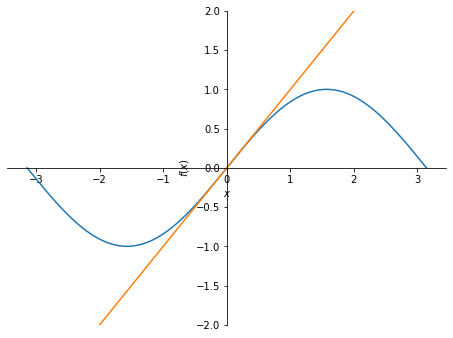

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
m = diff(sin(x), x).subs(x, 0)
plot(sin(x), m * x, (x, -pi, pi), ylim=(-2, 2));
```

</details>

#### Aufgabe 4.7

**Lineare Approximation:** Nähere √4,1 mit der Tangente an `√x` bei x₀ = 4 an. Gib den Näherungswert exakt, als Dezimalzahl mit 8 Ziffern
und darunter den genauen Wert `N(sqrt(4.1), 8)` aus.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{81}{40}$

$\displaystyle 2.025$

$\displaystyle 2.0248457$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = sqrt(x)
m = diff(f, x).subs(x, 4)
naeherung = m * (Rational('4.1') - 4) + 2
display(naeherung, N(naeherung, 8))
N(sqrt(Rational('4.1')), 8)
```

</details>

#### Aufgabe 4.8

In welchem Punkt hat der Graph von `f(x) = x² − 4x + 5` eine waagerechte Tangente? Gib den Punkt als Tupel aus.

**Erwartete Ausgabe:**

$\displaystyle \left( 2, \  1\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**2 - 4*x + 5
xs = solve(diff(f, x), x)[0]
(xs, f.subs(x, xs))
```

</details>

#### Aufgabe 4.9

An welchen Stellen ist die Tangente an `f(x) = x³/3 − x` parallel zur Geraden `y = 3x`?

**Erwartete Ausgabe:**

$\displaystyle \left[ -2, \  2\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(Eq(diff(x**3 / 3 - x, x), 3), x)
```

</details>

## 5. Monotonie

#### Monotoniesatz

Ist f'(x) > 0 auf einem Intervall, so ist f dort **streng monoton steigend**, ist f'(x) < 0, so ist f **streng monoton fallend**.
Die Umkehrung gilt nicht ganz: f(x) = x³ ist überall steigend, obwohl f'(0) = 0 ist.

Mit `solveset(diff(f, x) > 0, x, domain=S.Reals)` bestimmt man, wo f steigt. `is_increasing(f, Interval(a, b))` prüft das direkt.

In [ ]:
f = x**3 - 3*x
display(diff(f, x))
display(solveset(diff(f, x) > 0, x, domain=S.Reals))
display(solveset(diff(f, x) < 0, x, domain=S.Reals))
is_increasing(x**3, S.Reals)

#### Aufgabe 5.1

Bestimme, wo `f(x) = x² − 6x` steigt.

**Erwartete Ausgabe:**

$\displaystyle \left(3, \infty\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solveset(diff(x**2 - 6*x, x) > 0, x, domain=S.Reals)
```

</details>

#### Aufgabe 5.2

Bestimme, wo `f(x) = −x³ + 12x` fällt.

**Erwartete Ausgabe:**

$\displaystyle \left(-\infty, -2\right) \cup \left(2, \infty\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solveset(diff(-x**3 + 12*x, x) < 0, x, domain=S.Reals)
```

</details>

#### Aufgabe 5.3

Prüfe mit `is_increasing()`, ob `f(x) = x³ + x` auf ganz ℝ steigt.

**Erwartete Ausgabe:**

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
is_increasing(x**3 + x, S.Reals)
```

</details>

#### Aufgabe 5.4

Prüfe mit `is_decreasing()`, ob `f(x) = 1/x` auf dem Intervall (0, ∞) fällt.

**Erwartete Ausgabe:**

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
is_decreasing(1 / x, Interval.open(0, oo))
```

</details>

#### Aufgabe 5.5

Bestimme die Monotonie-Intervalle von `f(x) = x⁴ − 2x²`: Gib aus, wo f steigt und wo f fällt.

**Erwartete Ausgabe:**

$\displaystyle \left(-1, 0\right) \cup \left(1, \infty\right)$

$\displaystyle \left(-\infty, -1\right) \cup \left(0, 1\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f1 = diff(x**4 - 2*x**2, x)
display(solveset(f1 > 0, x, domain=S.Reals))
solveset(f1 < 0, x, domain=S.Reals)
```

</details>

#### Aufgabe 5.6

Zeichne `f(x) = x³ − 3x` und `f'(x)` in ein Diagramm für x von −2,5 bis 2,5. Wo f' positiv ist, steigt f.

**Erwartete Ausgabe:**



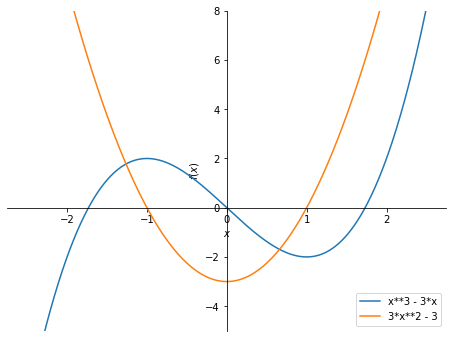

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 3*x
plot(f, diff(f, x), (x, -2.5, 2.5), ylim=(-5, 8), legend=True);
```

</details>

## 6. Extrempunkte

#### Hoch- und Tiefpunkte

An einer Extremstelle hat der Graph eine waagerechte Tangente: f'(x) = 0 (**notwendige Bedingung**).
Ob es ein Hoch- oder Tiefpunkt ist, entscheidet die zweite Ableitung (**hinreichende Bedingung**):

- f'(x₀) = 0 und f''(x₀) < 0: **Hochpunkt** (lokales Maximum)
- f'(x₀) = 0 und f''(x₀) > 0: **Tiefpunkt** (lokales Minimum)
- Ist f''(x₀) = 0, hilft ein Vorzeichenwechsel von f'.

Ein **lokales** Maximum ist der größte Wert in der Umgebung, ein **globales** der größte Wert überhaupt (auf einem Intervall).
`maximum(f, x, Interval(a, b))` liefert den globalen größten Wert auf dem Intervall.

In [ ]:
f = x**3 - 3*x
f1 = diff(f, x)
f2 = diff(f, x, 2)
for xe in solve(f1, x):
    art = 'Hochpunkt' if f2.subs(x, xe) < 0 else 'Tiefpunkt'
    print(art, (xe, f.subs(x, xe)))
maximum(f, x, Interval(-2, 3))

#### Aufgabe 6.1

Bestimme die Extremstelle von `f(x) = x² − 8x + 3`. Gib den Punkt als Tupel aus und darunter, ob `f''` dort positiv ist (dann ist es ein Tiefpunkt).

**Erwartete Ausgabe:**

$\displaystyle \left( 4, \  -13\right)$

$\displaystyle \text{True}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**2 - 8*x + 3
xe = solve(diff(f, x), x)[0]
display((xe, f.subs(x, xe)))
diff(f, x, 2).subs(x, xe) > 0
```

</details>

#### Aufgabe 6.2

Bestimme die Hoch- und Tiefpunkte von `f(x) = x³ − 12x`. Gib für jede Extremstelle Art und Punkt aus (wie im Beispiel mit `print`).

**Erwartete Ausgabe:**

```
Hochpunkt (-2, 16)
Tiefpunkt (2, -16)
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 12*x
for xe in solve(diff(f, x), x):
    art = 'Hochpunkt' if diff(f, x, 2).subs(x, xe) < 0 else 'Tiefpunkt'
    print(art, (xe, f.subs(x, xe)))
```

</details>

#### Aufgabe 6.3

Bestimme die Extrempunkte von `f(x) = −x⁴ + 2x²`.

**Erwartete Ausgabe:**

```
Hochpunkt (-1, 1)
Tiefpunkt (0, 0)
Hochpunkt (1, 1)
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = -x**4 + 2*x**2
for xe in solve(diff(f, x), x):
    art = 'Hochpunkt' if diff(f, x, 2).subs(x, xe) < 0 else 'Tiefpunkt'
    print(art, (xe, f.subs(x, xe)))
```

</details>

#### Aufgabe 6.4

Bestimme die Extremstellen von `f(x) = x³ − 6x² + 9x + 1` und die zugehörigen Werte von `f''`.

**Erwartete Ausgabe:**

$\displaystyle \left[ 1, \  3\right]$

$\displaystyle \left[ -6, \  6\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 6*x**2 + 9*x + 1
l = solve(diff(f, x), x)
display(l)
[diff(f, x, 2).subs(x, w) for w in l]
```

</details>

#### Aufgabe 6.5

`f(x) = x⁴` hat bei 0 die Ableitung 0 und auch `f''(0) = 0`. Prüfe das Vorzeichen von `f'` links und rechts von 0 (bei −0,1 und 0,1).

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 0$

$\displaystyle 0$

$\displaystyle \left[ - \frac{1}{250}, \  \frac{1}{250}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f1 = diff(x**4, x)
display(f1.subs(x, 0), diff(x**4, x, 2).subs(x, 0))
[f1.subs(x, Rational(-1, 10)), f1.subs(x, Rational(1, 10))]
```

</details>

#### Aufgabe 6.6

Bestimme den größten und den kleinsten Wert von `f(x) = x³ − 3x` auf dem Intervall [−3, 2] (globale Extrema).

**Erwartete Ausgabe:**

$\displaystyle 2$

$\displaystyle -18$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 3*x
display(maximum(f, x, Interval(-3, 2)))
minimum(f, x, Interval(-3, 2))
```

</details>

#### Aufgabe 6.7

Bestimme die Extrempunkte von `f(x) = sin(x) + cos(x)` im Intervall [0, 2π]. Gib die Stellen (mit `solveset`) und die Funktionswerte aus.

**Erwartete Ausgabe:**

$\displaystyle \left\{\frac{\pi}{4}, \frac{5 \pi}{4}\right\}$

$\displaystyle \left[ \sqrt{2}, \  - \sqrt{2}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = sin(x) + cos(x)
stellen = solveset(diff(f, x), x, domain=Interval(0, 2*pi))
display(stellen)
[simplify(f.subs(x, w)) for w in stellen]
```

</details>

#### Aufgabe 6.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
f = x**2
display(solve(diff(f, x), x))
display(diff(f, x, 2))
solve(diff(x**3, x), x)
```

In [ ]:
f = x**2
display(solve(diff(f, x), x))
display(diff(f, x, 2))
solve(diff(x**3, x), x)

## 7. Krümmung und Wendepunkte

#### Krümmungsverhalten und Wendepunkte

- f''(x) > 0: Der Graph ist **linksgekrümmt** (wie eine nach oben offene Schale), f' steigt.
- f''(x) < 0: Der Graph ist **rechtsgekrümmt**, f' fällt.
- An einem **Wendepunkt** wechselt die Krümmung: f''(x₀) = 0 und f'''(x₀) ≠ 0.
  Ein Wendepunkt mit waagerechter Tangente (f'(x₀) = 0) heißt **Sattelpunkt**.

In [ ]:
f = x**3 - 3*x**2 + 1
f2 = diff(f, x, 2)
display(f2)
display(solveset(f2 > 0, x, domain=S.Reals))
xw = solve(f2, x)[0]
display(diff(f, x, 3).subs(x, xw))
(xw, f.subs(x, xw))

#### Aufgabe 7.1

Bestimme den Wendepunkt von `f(x) = x³ + 3x²` als Tupel.

**Erwartete Ausgabe:**

$\displaystyle \left( -1, \  2\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 + 3*x**2
xw = solve(diff(f, x, 2), x)[0]
(xw, f.subs(x, xw))
```

</details>

#### Aufgabe 7.2

Bestimme, wo der Graph von `f(x) = x³ + 3x²` linksgekrümmt ist.

**Erwartete Ausgabe:**

$\displaystyle \left(-1, \infty\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solveset(diff(x**3 + 3*x**2, x, 2) > 0, x, domain=S.Reals)
```

</details>

#### Aufgabe 7.3

Bestimme die Wendestellen von `f(x) = x⁴ − 6x²`.

**Erwartete Ausgabe:**

$\displaystyle \left[ -1, \  1\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(diff(x**4 - 6*x**2, x, 2), x)
```

</details>

#### Aufgabe 7.4

Prüfe, ob `f(x) = x³` bei 0 einen Sattelpunkt hat: Gib `f'(0)`, `f''(0)` und `f'''(0)` als Liste aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 0, \  0, \  6\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
[diff(x**3, x, k).subs(x, 0) for k in range(1, 4)]
```

</details>

#### Aufgabe 7.5

Bestimme die Wendetangente von `f(x) = x³ − 3x² + 1` (Tangente im Wendepunkt).

**Erwartete Ausgabe:**

$\displaystyle 2 - 3 x$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 3*x**2 + 1
xw = solve(diff(f, x, 2), x)[0]
m = diff(f, x).subs(x, xw)
expand(m * (x - xw) + f.subs(x, xw))
```

</details>

#### Aufgabe 7.6

Zeichne `f(x) = x³ − 3x² + 1`, `f'` und `f''` für x von −1,5 bis 3,5 mit Legende.

**Erwartete Ausgabe:**



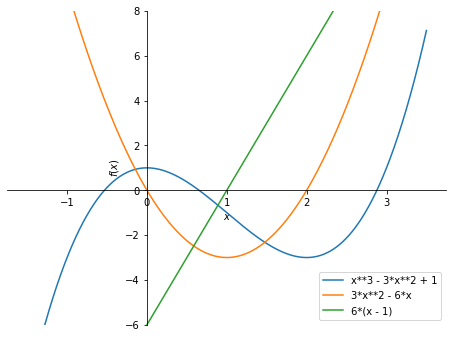

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 3*x**2 + 1
plot(f, diff(f, x), diff(f, x, 2), (x, -1.5, 3.5), ylim=(-6, 8), legend=True);
```

</details>

## 8. Kurvendiskussion

#### Eine Funktion vollständig untersuchen

Eine **Kurvendiskussion** fasst alles zusammen: Symmetrie, Nullstellen, Verhalten für x → ±∞, Extrempunkte, Wendepunkte, Graph.
Mit sympy prüfst du jeden Schritt.

In [ ]:
f = x**4 / 4 - 2*x**2
display(simplify(f.subs(x, -x) - f) == 0)
display(solve(f, x))
display(limit(f, x, oo))
f1, f2 = diff(f, x), diff(f, x, 2)
print('Extremstellen:', solve(f1, x), [f2.subs(x, w) for w in solve(f1, x)])
print('Wendestellen:', solve(f2, x))
plot(f, (x, -3.2, 3.2), ylim=(-5, 5));

#### Aufgabe 8.1

Untersuche `f(x) = x³ − 3x`: Gib Nullstellen, Extremstellen mit Art (Werte von f'') und Wendestelle jeweils mit `display()` aus und zeichne den Graphen
für x von −2,2 bis 2,2.

**Erwartete Ausgabe:**

$\displaystyle \left[ 0, \  - \sqrt{3}, \  \sqrt{3}\right]$

$\displaystyle \left[ -1, \  1\right]$

$\displaystyle \left[ -6, \  6\right]$

$\displaystyle \left[ 0\right]$

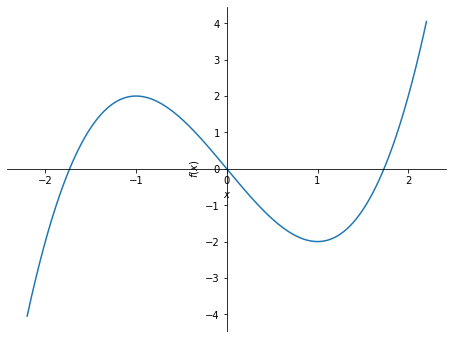

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 3*x
display(solve(f, x))
l = solve(diff(f, x), x)
display(l, [diff(f, x, 2).subs(x, w) for w in l])
display(solve(diff(f, x, 2), x))
plot(f, (x, -2.2, 2.2));
```

</details>

#### Aufgabe 8.2

Untersuche `f(x) = −x³ + 3x² − 4`: Gib Nullstellen mit Vielfachheit (`roots`), Extrempunkte und Wendepunkt (als Tupel) aus.

**Erwartete Ausgabe:**

$\displaystyle \left\{ -1 : 1, \  2 : 2\right\}$

$\displaystyle \left[ \left( 0, \  -4\right), \  \left( 2, \  0\right)\right]$

$\displaystyle \left( 1, \  -2\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = -x**3 + 3*x**2 - 4
display(roots(f, x))
display([(w, f.subs(x, w)) for w in solve(diff(f, x), x)])
xw = solve(diff(f, x, 2), x)[0]
(xw, f.subs(x, xw))
```

</details>

#### Aufgabe 8.3

Untersuche `f(x) = x⁴ − 4x³`: Gib die Extrempunkte, die Wendepunkte (als Tupel) und den Graphen für x von −1,5 bis 4,5 aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ \left( 0, \  0\right), \  \left( 3, \  -27\right)\right]$

$\displaystyle \left[ \left( 0, \  0\right), \  \left( 2, \  -16\right)\right]$

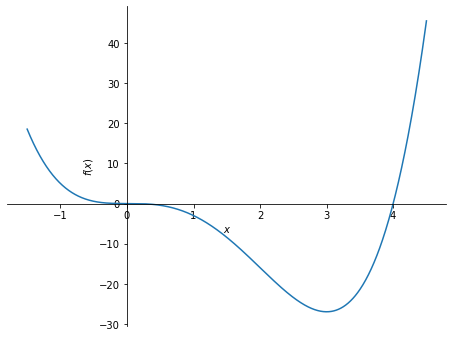

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**4 - 4*x**3
display([(w, f.subs(x, w)) for w in solve(diff(f, x), x)])
display([(w, f.subs(x, w)) for w in solve(diff(f, x, 2), x)])
plot(f, (x, -1.5, 4.5));
```

</details>

## 9. Optimierungsaufgaben

#### Extremwertaufgaben

So geht man vor:
1. **Zielfunktion** aufstellen (die Größe, die maximal oder minimal werden soll).
2. Mit einer **Nebenbedingung** auf eine Variable reduzieren.
3. **Definitionsbereich** überlegen.
4. Ableitung null setzen, Art prüfen, auch die Ränder betrachten.

Beispiel: Aus einem 20 cm × 20 cm großen Blech wird eine oben offene Schachtel gefaltet, indem man an den Ecken Quadrate der Seite x ausschneidet.
Das Volumen ist V(x) = x(20 − 2x)² mit 0 < x < 10.

In [ ]:
V = x * (20 - 2*x)**2
l = solveset(diff(V, x), x, domain=Interval.open(0, 10))
display(l)
xopt = list(l)[0]
display(diff(V, x, 2).subs(x, xopt))
display(V.subs(x, xopt))
plot(V, (x, 0, 10));

#### Aufgabe 9.1

Ein rechteckiger Garten soll mit 40 m Zaun eingezäunt werden. Welche Maße ergeben den größten Flächeninhalt? Sei x die Breite, die Länge ist 20 − x.
Gib die optimale Breite und den größten Flächeninhalt aus.

**Erwartete Ausgabe:**

$\displaystyle 10$

$\displaystyle 100$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
A = x * (20 - x)
xopt = solve(diff(A, x), x)[0]
display(xopt)
A.subs(x, xopt)
```

</details>

#### Aufgabe 9.2

Ein Garten liegt an einer Mauer, nur drei Seiten werden mit 60 m Zaun eingezäunt: zwei Seiten der Länge x und eine der Länge 60 − 2x.
Gib die optimale Seitenlänge x und den größten Flächeninhalt aus.

**Erwartete Ausgabe:**

$\displaystyle 15$

$\displaystyle 450$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
A = x * (60 - 2*x)
xopt = solve(diff(A, x), x)[0]
display(xopt)
A.subs(x, xopt)
```

</details>

#### Aufgabe 9.3

Aus einem 30 cm × 16 cm großen Karton wird eine oben offene Schachtel gefaltet (Eckquadrate der Seite x). Das Volumen ist `x(30 − 2x)(16 − 2x)` mit 0 < x < 8.
Gib die optimale Seite x und das größte Volumen aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{10}{3}$

$\displaystyle \frac{19600}{27}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
V = x * (30 - 2*x) * (16 - 2*x)
xopt = list(solveset(diff(V, x), x, domain=Interval.open(0, 8)))[0]
display(xopt)
V.subs(x, xopt)
```

</details>

#### Aufgabe 9.4

Die Summe zweier positiver Zahlen ist 12. Wann ist das Produkt aus der ersten Zahl und dem Quadrat der zweiten am größten? Sei x die erste Zahl.
Gib die erste Zahl und das größte Produkt aus.

**Erwartete Ausgabe:**

$\displaystyle 4$

$\displaystyle 256$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
P = x * (12 - x)**2
xopt = list(solveset(diff(P, x), x, domain=Interval.open(0, 12)))[0]
display(xopt)
P.subs(x, xopt)
```

</details>

#### Aufgabe 9.5

**Dose:** Eine zylindrische Dose soll 1 Liter (1000 cm³) fassen und möglichst wenig Blech verbrauchen. Mit dem Radius r ist die Höhe h = 1000/(πr²)
und die Oberfläche O(r) = 2πr² + 2000/r. Gib den optimalen Radius exakt und mit 4 Ziffern sowie die zugehörige Höhe mit 4 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{5 \cdot 2^{\frac{2}{3}}}{\sqrt[3]{\pi}}$

$\displaystyle 5.419$

$\displaystyle 10.84$

In [ ]:
r = symbols('r', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
r = symbols('r', positive=True)
O = 2*pi*r**2 + 2000 / r
ropt = solve(diff(O, r), r)[0]
display(ropt, N(ropt, 4))
N(1000 / (pi * ropt**2), 4)
```

</details>

#### Aufgabe 9.6

Welcher Punkt auf der Parabel `y = x²` liegt dem Punkt (0, 3) am nächsten? Minimiere das Quadrat des Abstands `d(x) = x² + (x² − 3)²`.
Gib die x-Werte und den kleinsten Abstand aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ - \frac{\sqrt{10}}{2}, \  \frac{\sqrt{10}}{2}\right]$

$\displaystyle \frac{\sqrt{11}}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
d = x**2 + (x**2 - 3)**2
l = [w for w in solve(diff(d, x), x) if diff(d, x, 2).subs(x, w) > 0]
display(l)
sqrt(d.subs(x, l[0]))
```

</details>

## 10. Gemischte Übungen

#### Aufgabe 10.1

Bestimme eine Parabel `f(x) = ax² + bx + c`, die durch (0, 1) geht und bei x = 2 einen Tiefpunkt mit dem Funktionswert −3 hat.
Stelle dazu drei Gleichungen auf (f(0) = 1, f(2) = −3, f'(2) = 0) und löse sie.

**Erwartete Ausgabe:**

$\displaystyle x^{2} - 4 x + 1$

In [ ]:
c = symbols('c')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
c = symbols('c')
f = a*x**2 + b*x + c
l = solve([Eq(f.subs(x, 0), 1), Eq(f.subs(x, 2), -3), Eq(diff(f, x).subs(x, 2), 0)], [a, b, c])
f.subs(l)
```

</details>

#### Aufgabe 10.2

Ein Körper bewegt sich nach dem Weg-Zeit-Gesetz `s(t) = t³ − 6t² + 9t` (t in s, s in m). Die Geschwindigkeit ist s'(t), die Beschleunigung s''(t).
Gib v(t) und a(t) aus und die Zeitpunkte, zu denen der Körper stillsteht.

**Erwartete Ausgabe:**

$\displaystyle 3 t^{2} - 12 t + 9$

$\displaystyle 6 \left(t - 2\right)$

$\displaystyle \left[ 1, \  3\right]$

In [ ]:
t = symbols('t')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
t = symbols('t')
s = t**3 - 6*t**2 + 9*t
v = diff(s, t)
display(v, diff(s, t, 2))
solve(v, t)
```

</details>

#### Aufgabe 10.3

Für welchen Wert von `k` hat `f(x) = x³ − kx` an der Stelle x = 2 eine waagerechte Tangente?

**Erwartete Ausgabe:**

$\displaystyle \left[ 12\right]$

In [ ]:
k = symbols('k')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k = symbols('k')
solve(Eq(diff(x**3 - k*x, x).subs(x, 2), 0), k)
```

</details>

#### Aufgabe 10.4

Bestimme die Gleichungen der beiden Tangenten an `f(x) = x²`, die durch den Punkt (0, −1) gehen. Für den Berührpunkt bei x₀ = u gilt:
Die Tangente u-abhängig aufstellen und den Punkt (0, −1) einsetzen.

**Erwartete Ausgabe:**

$\displaystyle \left[ - 2 x - 1, \  2 x - 1\right]$

In [ ]:
u = symbols('u')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
u = symbols('u')
tang = 2*u*(x - u) + u**2
l = solve(Eq(tang.subs(x, 0), -1), u)
[expand(tang.subs(u, w)) for w in l]
```

</details>

#### Aufgabe 10.5

Ein Unternehmen hat die Kostenfunktion `K(x) = x³ − 6x² + 15x + 10` und verkauft zum Preis von 12 pro Stück. Der Gewinn ist `G(x) = 12x − K(x)`.
Bei welcher Menge x > 0 ist der Gewinn maximal? Gib die Menge (mit 4 Ziffern) und den Gewinn (mit 4 Ziffern) aus.

**Erwartete Ausgabe:**

$\displaystyle 3.732$

$\displaystyle 10.39$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
G = 12*x - (x**3 - 6*x**2 + 15*x + 10)
l = [w for w in solve(diff(G, x), x) if diff(G, x, 2).subs(x, w) < 0]
display(N(l[0], 4))
N(G.subs(x, l[0]), 4)
```

</details>